In [1]:
# CELL 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from scipy.sparse import load_npz

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:

from google.colab import files

uploaded = files.upload()

Saving X_test_tfidf.npz to X_test_tfidf (1).npz
Saving Linear_SVM_Model.pkl to Linear_SVM_Model.pkl
Saving Naive_Bayes_Model.pkl to Naive_Bayes_Model.pkl
Saving Logistic_Regression_Model.pkl to Logistic_Regression_Model.pkl
Saving y_test.csv to y_test (1).csv


In [5]:
# CELL 3: Load Testing Data

X_test_tfidf = load_npz("X_test_tfidf.npz")

y_test = pd.read_csv("y_test.csv").iloc[:, 0]

print("Testing data loaded successfully!")

print("Testing Features Shape:", X_test_tfidf.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nTesting Label Distribution:")
print(y_test.value_counts())

Testing data loaded successfully!
Testing Features Shape: (640, 632)
Testing Labels Shape: (640,)

Testing Label Distribution:
label
INFORMATION       320
MISINFORMATION    320
Name: count, dtype: int64


In [6]:
# CELL 4: Load Machine Learning Models

with open("Logistic_Regression_Model.pkl", "rb") as file:
    lr_model = pickle.load(file)

with open("Naive_Bayes_Model.pkl", "rb") as file:
    nb_model = pickle.load(file)

with open("Linear_SVM_Model.pkl", "rb") as file:
    svm_model = pickle.load(file)

print("All models loaded successfully!")

All models loaded successfully!


In [7]:
# CELL 5: Predict Testing Data

lr_predictions = lr_model.predict(X_test_tfidf)

nb_predictions = nb_model.predict(X_test_tfidf)

svm_predictions = svm_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

print("Logistic Regression Predictions:",
      len(lr_predictions))

print("Naive Bayes Predictions:",
      len(nb_predictions))

print("Linear SVM Predictions:",
      len(svm_predictions))

Predictions generated successfully!
Logistic Regression Predictions: 640
Naive Bayes Predictions: 640
Linear SVM Predictions: 640


In [8]:
# CELL 6: Logistic Regression Metrics

lr_accuracy = accuracy_score(
    y_test, lr_predictions
)

lr_precision = precision_score(
    y_test,
    lr_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    lr_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    lr_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

print("LOGISTIC REGRESSION")
print("-------------------")

print("Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Precision:", round(lr_precision * 100, 2), "%")
print("Recall:", round(lr_recall * 100, 2), "%")
print("F1 Score:", round(lr_f1 * 100, 2), "%")

LOGISTIC REGRESSION
-------------------
Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %


In [9]:
# CELL 7: Naive Bayes Metrics

nb_accuracy = accuracy_score(
    y_test, nb_predictions
)

nb_precision = precision_score(
    y_test,
    nb_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

nb_recall = recall_score(
    y_test,
    nb_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

nb_f1 = f1_score(
    y_test,
    nb_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

print("NAIVE BAYES")
print("-----------")

print("Accuracy:", round(nb_accuracy * 100, 2), "%")
print("Precision:", round(nb_precision * 100, 2), "%")
print("Recall:", round(nb_recall * 100, 2), "%")
print("F1 Score:", round(nb_f1 * 100, 2), "%")

NAIVE BAYES
-----------
Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %


In [10]:
# CELL 8: Linear SVM Metrics

svm_accuracy = accuracy_score(
    y_test, svm_predictions
)

svm_precision = precision_score(
    y_test,
    svm_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    svm_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    svm_predictions,
    pos_label="MISINFORMATION",
    zero_division=0
)

print("LINEAR SVM")
print("-----------")

print("Accuracy:", round(svm_accuracy * 100, 2), "%")
print("Precision:", round(svm_precision * 100, 2), "%")
print("Recall:", round(svm_recall * 100, 2), "%")
print("F1 Score:", round(svm_f1 * 100, 2), "%")

LINEAR SVM
-----------
Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %


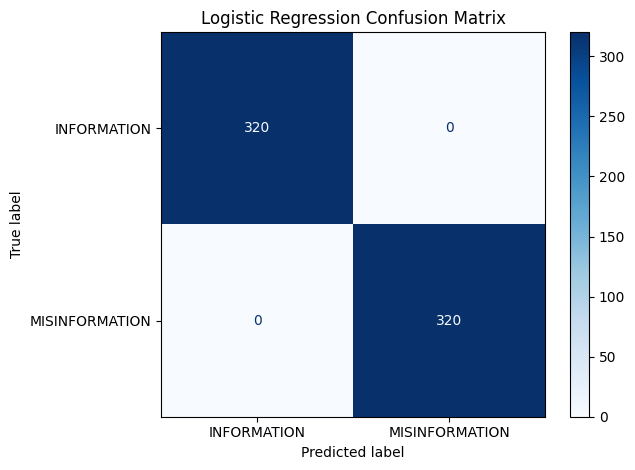

<Figure size 640x480 with 0 Axes>

In [11]:
# CELL 9: Logistic Regression Confusion Matrix

labels = ["INFORMATION", "MISINFORMATION"]

cm_lr = confusion_matrix(
    y_test,
    lr_predictions,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=labels
)

disp.plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

plt.savefig(
    "Confusion_Matrix_LR.png",
    dpi=300,
    bbox_inches="tight"
)

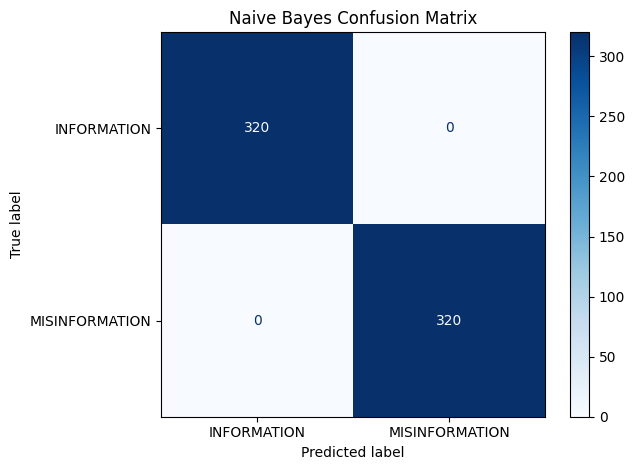

<Figure size 640x480 with 0 Axes>

In [12]:
# CELL 10: Naive Bayes Confusion Matrix

cm_nb = confusion_matrix(
    y_test,
    nb_predictions,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=labels
)

disp.plot(cmap="Blues")

plt.title("Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()

plt.savefig(
    "Confusion_Matrix_NB.png",
    dpi=300,
    bbox_inches="tight"
)

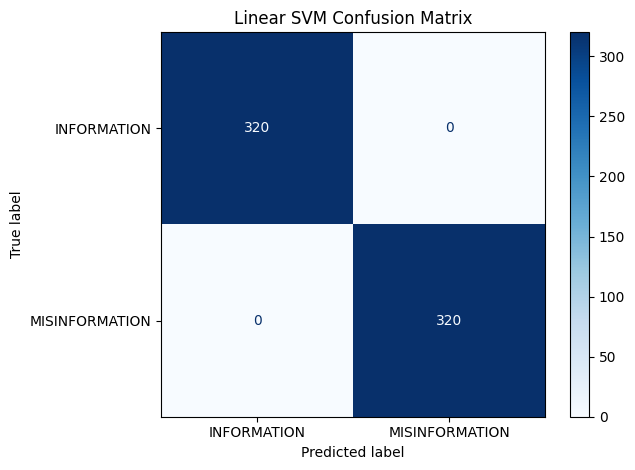

<Figure size 640x480 with 0 Axes>

In [13]:
# CELL 11: Linear SVM Confusion Matrix

cm_svm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=labels
)

disp.plot(cmap="Blues")

plt.title("Linear SVM Confusion Matrix")
plt.tight_layout()
plt.show()

plt.savefig(
    "Confusion_Matrix_SVM.png",
    dpi=300,
    bbox_inches="tight"
)

In [14]:
# CELL 12

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        lr_predictions,
        zero_division=0
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
                precision    recall  f1-score   support

   INFORMATION       1.00      1.00      1.00       320
MISINFORMATION       1.00      1.00      1.00       320

      accuracy                           1.00       640
     macro avg       1.00      1.00      1.00       640
  weighted avg       1.00      1.00      1.00       640



In [15]:
# CELL 13

print("NAIVE BAYES CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        nb_predictions,
        zero_division=0
    )
)

NAIVE BAYES CLASSIFICATION REPORT
                precision    recall  f1-score   support

   INFORMATION       1.00      1.00      1.00       320
MISINFORMATION       1.00      1.00      1.00       320

      accuracy                           1.00       640
     macro avg       1.00      1.00      1.00       640
  weighted avg       1.00      1.00      1.00       640



In [16]:
# CELL 14

print("LINEAR SVM CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        svm_predictions,
        zero_division=0
    )
)

LINEAR SVM CLASSIFICATION REPORT
                precision    recall  f1-score   support

   INFORMATION       1.00      1.00      1.00       320
MISINFORMATION       1.00      1.00      1.00       320

      accuracy                           1.00       640
     macro avg       1.00      1.00      1.00       640
  weighted avg       1.00      1.00      1.00       640



In [17]:
# CELL 15: Model Evaluation Comparison

evaluation_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],

    "Accuracy": [
        lr_accuracy,
        nb_accuracy,
        svm_accuracy
    ],

    "Precision": [
        lr_precision,
        nb_precision,
        svm_precision
    ],

    "Recall": [
        lr_recall,
        nb_recall,
        svm_recall
    ],

    "F1_Score": [
        lr_f1,
        nb_f1,
        svm_f1
    ]
})

# Convert values to percentages
for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score"
]:
    evaluation_results[column] *= 100

display(evaluation_results.round(2))

,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Naive Bayes,100.0,100.0,100.0,100.0
2,Linear SVM,100.0,100.0,100.0,100.0


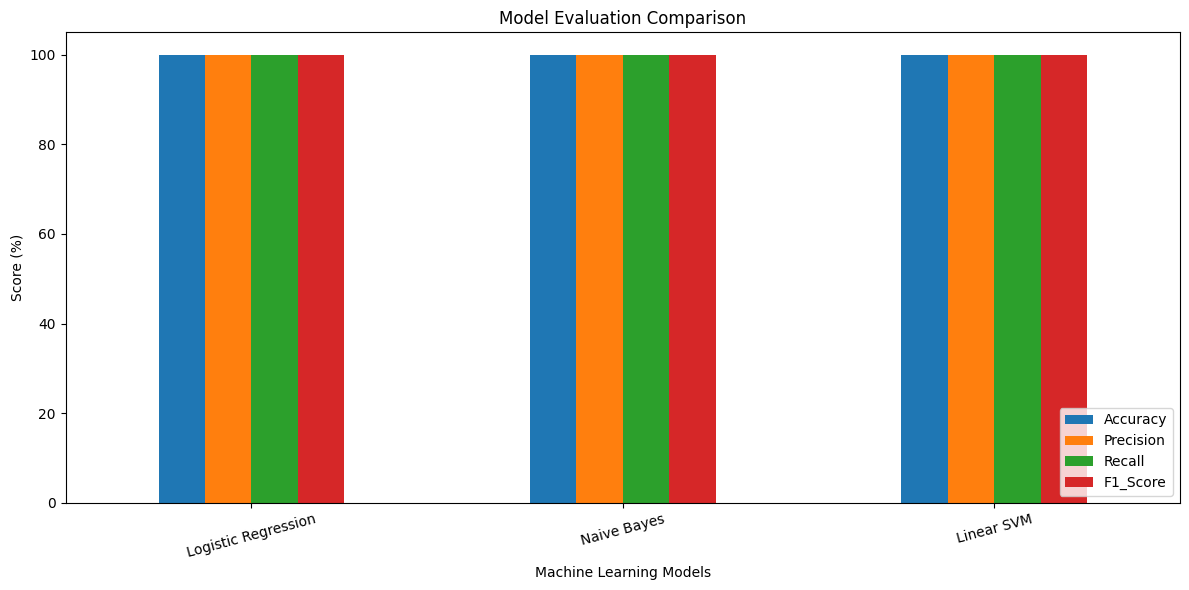

In [18]:
# CELL 16: Model Comparison Graph

evaluation_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1_Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Evaluation Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Machine Learning Models")

plt.xticks(rotation=15)
plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    "Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
# CELL 17: Best Model Selection

best_model_index = evaluation_results[
    "F1_Score"
].idxmax()

best_model = evaluation_results.loc[
    best_model_index
]

print("BEST MODEL BASED ON MISINFORMATION F1-SCORE")
print("------------------------------------------")

print("Model:", best_model["Model"])

print("Accuracy:",
      round(best_model["Accuracy"], 2), "%")

print("Precision:",
      round(best_model["Precision"], 2), "%")

print("Recall:",
      round(best_model["Recall"], 2), "%")

print("F1 Score:",
      round(best_model["F1_Score"], 2), "%")

BEST MODEL BASED ON MISINFORMATION F1-SCORE
------------------------------------------
Model: Logistic Regression
Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %


In [20]:
# CELL 18: Save Results

evaluation_results.to_csv(
    "Model_Evaluation_Results.csv",
    index=False
)

print("Evaluation Results Saved!")

Evaluation Results Saved!


In [21]:
# CELL 19: Save Classification Reports

reports = {}

for model_name, predictions in [
    ("Logistic Regression", lr_predictions),
    ("Naive Bayes", nb_predictions),
    ("Linear SVM", svm_predictions)
]:

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    reports[model_name] = pd.DataFrame(report).transpose()

with open("Classification_Report.csv", "w") as file:

    for model_name, report_df in reports.items():

        file.write(model_name + "\n")

        report_df.to_csv(file)

        file.write("\n\n")

print("Classification Reports Saved!")

Classification Reports Saved!


In [22]:
from google.colab import files

files.download("Model_Evaluation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
files.download("Classification_Report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
files.download("Model_Comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
files.download("Confusion_Matrix_LR.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
files.download("Confusion_Matrix_NB.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
files.download("Confusion_Matrix_SVM.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
print("STEP 8: MODEL EVALUATION")
print("========================")

display(evaluation_results.round(2))

print("\nBest Model:", best_model["Model"])

print("\nSTEP 8 COMPLETED SUCCESSFULLY!")

STEP 8: MODEL EVALUATION


,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Naive Bayes,100.0,100.0,100.0,100.0
2,Linear SVM,100.0,100.0,100.0,100.0



Best Model: Logistic Regression

STEP 8 COMPLETED SUCCESSFULLY!
